In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

from belfast.isochrone_utils import read_isochrones
from belfast.paths import REPO_ROOT, RESULTS_DIR, DATA_DIR
from belfast.cluster_utils import summarize_cluster_age, plot_cluster_age_2d


## Select a sampling configuration

In [2]:
configuration = 'PARSEC_DIRECT_spec_MH_rot'
# configuration = 'PARSEC_PARS_spec_MH_rot'
# configuration = 'PARSEC_DIRECT_spec_MH_non_rot'
# configuration = 'PARSEC_DIRECT_default_MH_rot'

## Summarize sampling reuslts

In [9]:
# Hyades
df_post_hyades = summarize_cluster_age(
    samples_glob        = RESULTS_DIR / f'clusters_{configuration}/Hyades/*/posterior.npz',
    df_targets_path     = DATA_DIR / 'clusters/Hyades_finalized_targets.csv',
    save_name           = DATA_DIR / f'clusters/Hyades_posterior_summary_{configuration}.csv',
    verbose             = False,
)

# Praesepe
df_post_praesepe = summarize_cluster_age(
    samples_glob        = RESULTS_DIR / f'clusters_{configuration}/Praesepe/*/posterior.npz',
    df_targets_path     = DATA_DIR / 'clusters/Praesepe_finalized_targets.csv',
    save_name           = DATA_DIR / f'clusters/Praesepe_posterior_summary_{configuration}.csv',
    verbose             = False,
)

# Pleiades
df_post_pleiades = summarize_cluster_age(
    samples_glob        = RESULTS_DIR / f'clusters_{configuration}/Pleiades/*/posterior.npz',
    df_targets_path     = DATA_DIR / 'clusters/Pleiades_finalized_targets.csv',
    save_name           = DATA_DIR / f'clusters/Pleiades_posterior_summary_{configuration}.csv',
    verbose             = False,
)

## Plot CMDs and clsuter ages

[Hyades CMD] No exclusions requested; keeping 8 rows.
[Praesepe CMD] Removed 2 row(s): ['HIP 42485', 'HIP 42578']
[Pleiades CMD] Removed 1 row(s): ['HD 23629']

Hyades: 8 stars finally used
  HIP 20635       weight = 0.999
  HIP 23497       weight = 0.990
  HIP 20641       weight = 0.998
  HIP 20261       weight = 0.999
  HIP 21670       weight = 0.990
  HIP 22044       weight = 0.999
  HIP 18735       weight = 0.984
  HIP 18170       weight = 0.992

2D Age-[M/H] combination:
  Age = 661.1 -24.2 +25.6 Myr
  [M/H] = 0.217 -0.038 +0.032

1D Age combination:
  Age = 732.2 -25.1 +28.4 Myr

Praesepe: 8 stars finally used
  HD 73711        weight = 1.000
  HIP 42164       weight = 0.957
  HIP 42993       weight = 1.000
  HIP 43050       weight = 1.000
  HIP 42952       weight = 1.000
  HD 73818        weight = 1.000
  HIP 42766       weight = 1.000
  HD 73854        weight = 1.000

2D Age-[M/H] combination:
  Age = 644.3 -32.6 +30.5 Myr
  [M/H] = 0.204 -0.039 +0.035

1D Age combination:
  Ag

/Users/ziyinggu/Programming/GitHub/BELFAST/belfast/cluster_utils.py:1526: UserWarning: Some Age samples fall outside the grid and may be truncated.
  age_grid, MH_grid = _build_age_mh_grids(



2D Age-[M/H] combination:
  Age = 185.1 -26.9 +23.6 Myr
  [M/H] = -0.014 -0.039 +0.036

1D Age combination:
  Age = 178.5 -16.9 +17.4 Myr


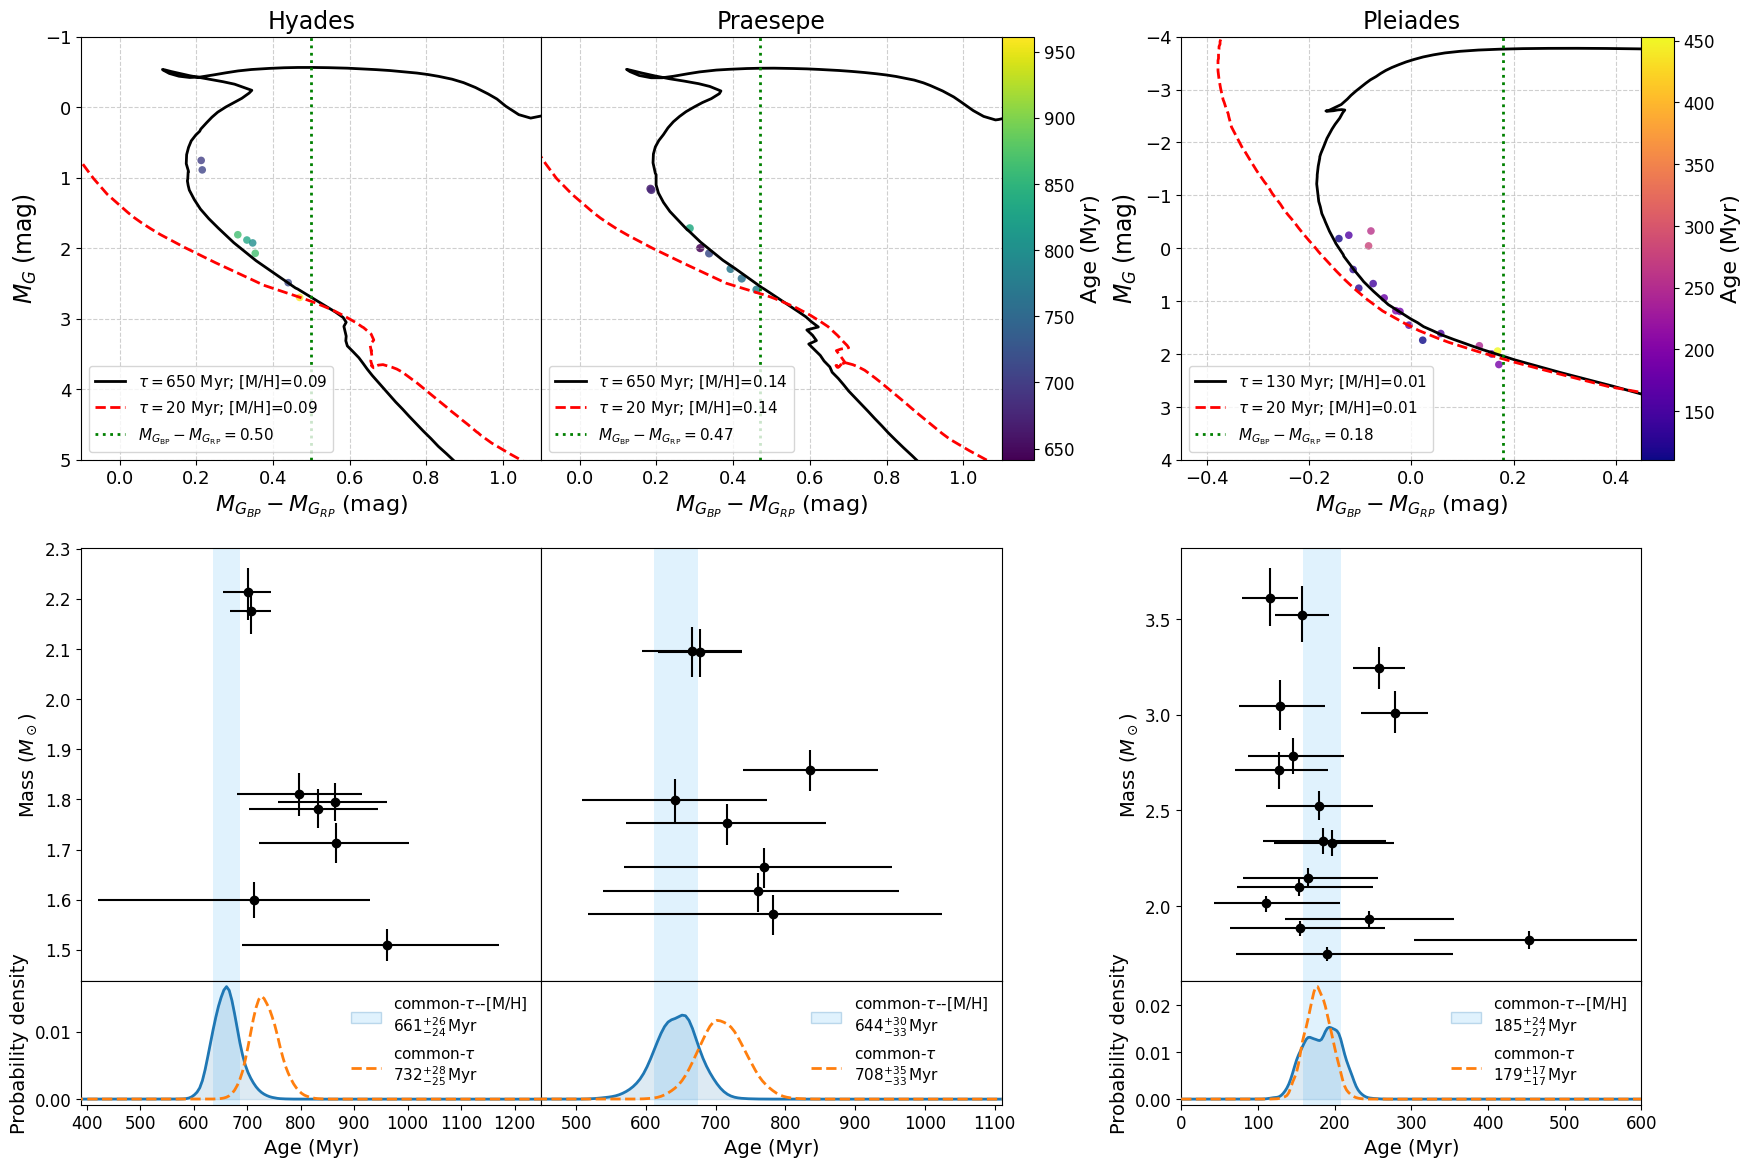

In [13]:
inc = "60"      # Inclination angle of the plotted isochrones, in degrees.
n_grid = 400    # Number of grid points along each dimension of the KDE grid.


# Independent exclusions for CMD and cluster-age panels
CMD_DROPPED_LISTS = {
    "Hyades": [],
    "Praesepe": [
        "HIP 42485",  # high SGB risk
        "HIP 42578",  # high SGB risk
    ],
    "Pleiades": [
        "HD 23629",   # possible binary; Torres+2020 referred to McGraw+1974
    ],
}

CLUSTER_AGE_DROPPED_LISTS = {
    "Hyades": [],
    "Praesepe": [
        "HIP 42485",  # high SGB risk
        "HIP 42578",  # high SGB risk
    ],
    "Pleiades": [
        "HD 23629",   # possible binary; Torres+2020 referred to McGraw+1974
    ],
}



# ============================================================
# Read posterior results
# ============================================================

df_post_hyades_path = DATA_DIR / f"clusters/Hyades_posterior_summary_{configuration}.csv"
df_post_praesepe_path = DATA_DIR / f"clusters/Praesepe_posterior_summary_{configuration}.csv"
df_post_pleiades_path = DATA_DIR / f"clusters/Pleiades_posterior_summary_{configuration}.csv"

df_post_hyades = pd.read_csv(df_post_hyades_path)
df_post_praesepe = pd.read_csv(df_post_praesepe_path)
df_post_pleiades = pd.read_csv(df_post_pleiades_path)

# ============================================================
# Read isochrones
# ============================================================

# Hyades
iso_hyades = read_isochrones("/Users/ziyinggu/Downloads/omega_ini0.8_MH0.09_Age650.dat", show_progress=False)
iso_beta_pic_hyades = read_isochrones(
    DATA_DIR / "clusters/reference_isochrones/20Myr_MH_+0.09_omega_ini_0.8.dat",
    show_progress=False,
)

Hyades_G = iso_hyades[0][f"G_i{inc}"].values
Hyades_G_BP = iso_hyades[0][f"G_BP_i{inc}"].values
Hyades_G_RP = iso_hyades[0][f"G_RP_i{inc}"].values
Beta_Pic_Hyades_G = iso_beta_pic_hyades[0][f"G_i{inc}"].values
Beta_Pic_Hyades_G_BP = iso_beta_pic_hyades[0][f"G_BP_i{inc}"].values
Beta_Pic_Hyades_G_RP = iso_beta_pic_hyades[0][f"G_RP_i{inc}"].values

# Praesepe
iso_praesepe = read_isochrones("/Users/ziyinggu/Downloads/omega_ini0.8_MH0.14_Age650.dat", show_progress=False)
iso_beta_pic_praesepe = read_isochrones(
    DATA_DIR / "clusters/reference_isochrones/20Myr_MH_+0.14_omega_ini_0.8.dat",
    show_progress=False,
)

Praesepe_G = iso_praesepe[0][f"G_i{inc}"].values
Praesepe_G_BP = iso_praesepe[0][f"G_BP_i{inc}"].values
Praesepe_G_RP = iso_praesepe[0][f"G_RP_i{inc}"].values
Beta_Pic_Praesepe_G = iso_beta_pic_praesepe[0][f"G_i{inc}"].values
Beta_Pic_Praesepe_G_BP = iso_beta_pic_praesepe[0][f"G_BP_i{inc}"].values
Beta_Pic_Praesepe_G_RP = iso_beta_pic_praesepe[0][f"G_RP_i{inc}"].values

# Pleiades
iso_pleiades = read_isochrones("/Users/ziyinggu/Downloads/omega_ini0.8_MH0.01_Age130.dat", show_progress=False)
iso_beta_pic_pleiades = read_isochrones(
    DATA_DIR / "clusters/reference_isochrones/20Myr_MH_+0.01_omega_ini_0.8.dat",
    show_progress=False,
)

Pleiades_G = iso_pleiades[0][f"G_i{inc}"].values
Pleiades_G_BP = iso_pleiades[0][f"G_BP_i{inc}"].values
Pleiades_G_RP = iso_pleiades[0][f"G_RP_i{inc}"].values
Beta_Pic_Pleiades_G = iso_beta_pic_pleiades[0][f"G_i{inc}"].values
Beta_Pic_Pleiades_G_BP = iso_beta_pic_pleiades[0][f"G_BP_i{inc}"].values
Beta_Pic_Pleiades_G_RP = iso_beta_pic_pleiades[0][f"G_RP_i{inc}"].values

# ============================================================
# Exclude stars from CMD
# ============================================================

def exclude_stars_from_cmd(df, dropped_names, cluster_name):
    """Exclude CMD targets by exact matches in posterior_name."""
    if "posterior_name" not in df.columns:
        raise KeyError(f"'posterior_name' column not found in {cluster_name} dataframe.")

    dropped_names = [str(name) for name in dropped_names]
    if not dropped_names:
        print(f"[{cluster_name} CMD] No exclusions requested; keeping {len(df)} rows.")
        return df.copy()

    remove_mask = df["posterior_name"].isin(dropped_names)
    removed_names = df.loc[remove_mask, "posterior_name"].tolist()
    not_found = sorted(set(dropped_names) - set(removed_names))

    print(f"[{cluster_name} CMD] Removed {int(remove_mask.sum())} row(s): {removed_names}")
    if not_found:
        print(f"[{cluster_name} CMD] WARNING: targets not found in posterior_name: {not_found}")

    return df.loc[~remove_mask].copy()


# Filtered copies for CMD only; retain original dataframes for cluster-age analysis
df_cmd_hyades = exclude_stars_from_cmd(df_post_hyades, CMD_DROPPED_LISTS["Hyades"], "Hyades")
df_cmd_praesepe = exclude_stars_from_cmd(df_post_praesepe, CMD_DROPPED_LISTS["Praesepe"], "Praesepe")
df_cmd_pleiades = exclude_stars_from_cmd(df_post_pleiades, CMD_DROPPED_LISTS["Pleiades"], "Pleiades")

# ============================================================
# Color normalization for CMD
# Hyades + Praesepe share one norm; Pleiades has its own norm
# ============================================================

ages_hp = np.concatenate([
    df_cmd_hyades["age"].dropna().values,
    df_cmd_praesepe["age"].dropna().values,
])

norm_hp = mcolors.Normalize(vmin=ages_hp.min(), vmax=ages_hp.max())
norm_pl = mcolors.Normalize(
    vmin=df_cmd_pleiades["age"].dropna().min(),
    vmax=df_cmd_pleiades["age"].dropna().max(),
)

cmap_hp, cmap_pl = plt.cm.viridis, plt.cm.plasma

# ============================================================
# Create combined figure
#
# Top: CMD
# Bottom: Mass vs Age and probability density vs Age
# Columns: Hyades | Praesepe | HP cbar | gap | Pleiades | Pleiades cbar
# ============================================================

fig = plt.figure(figsize=(17.5, 12.0))
gs = GridSpec(
    2, 6, figure=fig,
    width_ratios=[1.0, 1.0, 0.07, 0.32, 1.0, 0.07],
    height_ratios=[1.9, 2.5], wspace=0.0, hspace=0.18,
)

# ============================================================
# Top row: CMD axes
# ============================================================

ax_cmd_h = fig.add_subplot(gs[0, 0])
ax_cmd_p = fig.add_subplot(gs[0, 1], sharey=ax_cmd_h)
cax_hp = fig.add_subplot(gs[0, 2])
ax_gap_top = fig.add_subplot(gs[0, 3])
ax_gap_top.axis("off")
ax_cmd_pl = fig.add_subplot(gs[0, 4])
cax_pl = fig.add_subplot(gs[0, 5])

# ============================================================
# Bottom row: nested grids
# Mass-age and probability density panels have no vertical gap
# ============================================================

height_ratios = [3.5, 1]

# Hyades
gs_h = gs[1, 0].subgridspec(2, 1, height_ratios=height_ratios, hspace=0.0)
ax_h_top = fig.add_subplot(gs_h[0, 0])
ax_h_bot = fig.add_subplot(gs_h[1, 0], sharex=ax_h_top)

# Praesepe
gs_p = gs[1, 1].subgridspec(2, 1, height_ratios=height_ratios, hspace=0.0)
ax_p_top = fig.add_subplot(gs_p[0, 0], sharey=ax_h_top)
ax_p_bot = fig.add_subplot(gs_p[1, 0], sharex=ax_p_top, sharey=ax_h_bot)

# Pleiades
gs_pl = gs[1, 4].subgridspec(2, 1, height_ratios=height_ratios, hspace=0.0)
ax_pl_top = fig.add_subplot(gs_pl[0, 0])
ax_pl_bot = fig.add_subplot(gs_pl[1, 0], sharex=ax_pl_top)

# Empty bottom-row columns
ax_bottom_cbar_hp = fig.add_subplot(gs[1, 2])
ax_bottom_gap = fig.add_subplot(gs[1, 3])
ax_bottom_cbar_pl = fig.add_subplot(gs[1, 5])
for ax in (ax_bottom_cbar_hp, ax_bottom_gap, ax_bottom_cbar_pl):
    ax.axis("off")

# ============================================================
# Hyades CMD
# ============================================================

sc_hp = ax_cmd_h.scatter(
    df_cmd_hyades["MBP_MRP"], df_cmd_hyades["MG"],
    c=df_cmd_hyades["age"], cmap=cmap_hp, norm=norm_hp,
    s=30, alpha=0.8, edgecolors="none",
)
ax_cmd_h.plot(Hyades_G_BP - Hyades_G_RP, Hyades_G, color="black", linewidth=2,
              label=r"$\tau=650$ Myr; [M/H]=0.09")
ax_cmd_h.plot(Beta_Pic_Hyades_G_BP - Beta_Pic_Hyades_G_RP, Beta_Pic_Hyades_G,
              color="red", linestyle="--", linewidth=2,
              label=r"$\tau=20$ Myr; [M/H]=0.09")

x_line_hyades = 0.50
ax_cmd_h.axvline(
    x=x_line_hyades, linestyle=":", color="green", linewidth=2,
    label=rf"$M_{{G_{{\mathrm{{BP}}}}}}-M_{{G_{{\mathrm{{RP}}}}}}={x_line_hyades:.2f}$",
)
ax_cmd_h.set_xlim(-0.1, 1.1)
ax_cmd_h.set_ylim(-1, 5)
ax_cmd_h.invert_yaxis()
ax_cmd_h.set_title("Hyades", fontsize=17)
ax_cmd_h.set_ylabel(r"$M_{\mathit{G}} \;(\mathrm{mag})$", fontsize=17)
ax_cmd_h.set_xlabel(r"$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$", fontsize=16)
ax_cmd_h.grid(True, linestyle="--", alpha=0.6)
ax_cmd_h.tick_params(axis="both", labelsize=13)
ax_cmd_h.legend(fontsize=11, loc="lower left")

# ============================================================
# Praesepe CMD
# ============================================================

ax_cmd_p.scatter(
    df_cmd_praesepe["MBP_MRP"], df_cmd_praesepe["MG"],
    c=df_cmd_praesepe["age"], cmap=cmap_hp, norm=norm_hp,
    s=35, alpha=0.85, edgecolors="none",
)
ax_cmd_p.plot(Praesepe_G_BP - Praesepe_G_RP, Praesepe_G, color="black", linewidth=2,
              label=r"$\tau=650$ Myr; [M/H]=0.14")
ax_cmd_p.plot(Beta_Pic_Praesepe_G_BP - Beta_Pic_Praesepe_G_RP, Beta_Pic_Praesepe_G,
              color="red", linestyle="--", linewidth=2,
              label=r"$\tau=20$ Myr; [M/H]=0.14")

x_line_praesepe = 0.47
ax_cmd_p.axvline(
    x=x_line_praesepe, linestyle=":", color="green", linewidth=2,
    label=rf"$M_{{G_{{\mathrm{{BP}}}}}}-M_{{G_{{\mathrm{{RP}}}}}}={x_line_praesepe:.2f}$",
)
ax_cmd_p.set_xlim(-0.1, 1.1)
ax_cmd_p.set_title("Praesepe", fontsize=17)
ax_cmd_p.set_xlabel(r"$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$", fontsize=16)
ax_cmd_p.grid(True, linestyle="--", alpha=0.6)
ax_cmd_p.tick_params(axis="both", labelsize=13)
ax_cmd_p.tick_params(axis="y", left=False, labelleft=False)
ax_cmd_p.legend(fontsize=11, loc="lower left")

# ============================================================
# Pleiades CMD
# ============================================================

special_hd_ids = []
mask_special = df_cmd_pleiades["HD_ID"].astype(str).isin([str(x) for x in special_hd_ids])
mask_normal = ~mask_special

sc_pl = ax_cmd_pl.scatter(
    df_cmd_pleiades.loc[mask_normal, "MBP_MRP"],
    df_cmd_pleiades.loc[mask_normal, "MG"],
    c=df_cmd_pleiades.loc[mask_normal, "age"], cmap=cmap_pl, norm=norm_pl,
    s=30, alpha=0.8, marker="o", edgecolors="none",
)
ax_cmd_pl.scatter(
    df_cmd_pleiades.loc[mask_special, "MBP_MRP"],
    df_cmd_pleiades.loc[mask_special, "MG"],
    c=df_cmd_pleiades.loc[mask_special, "age"], cmap=cmap_pl, norm=norm_pl,
    s=45, alpha=1.0, marker="^", edgecolors="none",
)
ax_cmd_pl.plot(Pleiades_G_BP - Pleiades_G_RP, Pleiades_G, color="black", linewidth=2,
               label=r"$\tau=130$ Myr; [M/H]=0.01")
ax_cmd_pl.plot(Beta_Pic_Pleiades_G_BP - Beta_Pic_Pleiades_G_RP, Beta_Pic_Pleiades_G,
               color="red", linestyle="--", linewidth=2,
               label=r"$\tau=20$ Myr; [M/H]=0.01")

x_line_pleiades = 0.18
ax_cmd_pl.axvline(
    x=x_line_pleiades, linestyle=":", color="green", linewidth=2,
    label=rf"$M_{{G_{{\mathrm{{BP}}}}}}-M_{{G_{{\mathrm{{RP}}}}}}={x_line_pleiades:.2f}$",
)
ax_cmd_pl.set_xlim(-0.45, 0.45)
ax_cmd_pl.set_ylim(-4, 4)
ax_cmd_pl.invert_yaxis()
ax_cmd_pl.set_title("Pleiades", fontsize=17)
ax_cmd_pl.set_xlabel(r"$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$", fontsize=16)
ax_cmd_pl.set_ylabel(r"$M_{\mathit{G}} \;(\mathrm{mag})$", fontsize=17)
ax_cmd_pl.grid(True, linestyle="--", alpha=0.6)
ax_cmd_pl.tick_params(axis="both", labelsize=13)
ax_cmd_pl.legend(fontsize=11, loc="lower left")

# ============================================================
# CMD colorbars
# ============================================================

sm_hp = plt.cm.ScalarMappable(norm=norm_hp, cmap=cmap_hp)
sm_hp.set_array([])
cbar_hp = fig.colorbar(sm_hp, cax=cax_hp)
cbar_hp.set_label("Age (Myr)", fontsize=16)
cbar_hp.ax.tick_params(labelsize=12)
cbar_hp.ax.yaxis.set_ticks_position("right")
cbar_hp.ax.yaxis.set_label_position("right")

sm_pl = plt.cm.ScalarMappable(norm=norm_pl, cmap=cmap_pl)
sm_pl.set_array([])
cbar_pl = fig.colorbar(sm_pl, cax=cax_pl)
cbar_pl.set_label("Age (Myr)", fontsize=16)
cbar_pl.ax.tick_params(labelsize=12)

# ============================================================
# Bottom panels: cluster age
# ============================================================

# Hyades
result_hyades = plot_cluster_age_2d(
    cluster="Hyades", df_post_path=df_post_hyades_path,
    dropped_list=CLUSTER_AGE_DROPPED_LISTS["Hyades"], weight="HYA",
    MH_prior_median=0.090, MH_prior_std=0.079,
    age_range=(0, 2000), age_xlim=(390, 1250), MH_range=(-0.4, 0.4),
    n_age_grid=n_grid, n_MH_grid=n_grid, title=False, legend_loc="upper right",
    axes=(ax_h_top, ax_h_bot), save_name=None, show=False,
)

# Praesepe
result_praesepe = plot_cluster_age_2d(
    cluster="Praesepe", df_post_path=df_post_praesepe_path,
    dropped_list=CLUSTER_AGE_DROPPED_LISTS["Praesepe"], weight="PRAE",
    MH_prior_median=0.140, MH_prior_std=0.093,
    age_range=(0, 2000), age_xlim=(450, 1110), MH_range=(-0.4, 0.4),
    n_age_grid=n_grid, n_MH_grid=n_grid, title=False, legend_loc="upper right",
    axes=(ax_p_top, ax_p_bot), save_name=None, show=False,
)

# Pleiades
result_pleiades = plot_cluster_age_2d(
    cluster="Pleiades", df_post_path=df_post_pleiades_path,
    dropped_list=CLUSTER_AGE_DROPPED_LISTS["Pleiades"], weight="PLE",
    MH_prior_median=0.010, MH_prior_std=0.090,
    age_range=(0, 1000), age_xlim=(0, 600), MH_range=(-0.4, 0.4),
    n_age_grid=n_grid, n_MH_grid=n_grid, title=False, legend_loc="upper right",
    axes=(ax_pl_top, ax_pl_bot), save_name=None, show=False,
)

# ============================================================
# Bottom-panel formatting
# ============================================================

for ax in (ax_h_top, ax_p_top, ax_pl_top):
    ax.tick_params(axis="x", labelbottom=False)
    ax.set_title("", fontsize=14)

# Hide Praesepe y-axis labels
for ax in (ax_p_top, ax_p_bot):
    ax.tick_params(axis="y", left=False, labelleft=False)
    ax.set_ylabel("")

# Y-axis labels
ax_h_top.set_ylabel(r"Mass ($M_\odot$)", fontsize=14)
ax_h_bot.set_ylabel("Probability density", fontsize=14)
ax_pl_top.set_ylabel(r"Mass ($M_\odot$)", fontsize=14)
ax_pl_bot.set_ylabel("Probability density", fontsize=14)

# X-axis labels
ax_h_bot.set_xlabel("Age (Myr)", fontsize=14)
ax_p_bot.set_xlabel("Age (Myr)", fontsize=14)
ax_pl_bot.set_xlabel("Age (Myr)", fontsize=14)

# Explicit y-limits for shared axes
top_ymin = min(ax_h_top.get_ylim()[0], ax_p_top.get_ylim()[0])
top_ymax = max(ax_h_top.get_ylim()[1], ax_p_top.get_ylim()[1])
ax_h_top.set_ylim(top_ymin, top_ymax)

bot_ymin = min(ax_h_bot.get_ylim()[0], ax_p_bot.get_ylim()[0])
bot_ymax = max(ax_h_bot.get_ylim()[1], ax_p_bot.get_ylim()[1])
ax_h_bot.set_ylim(bot_ymin, bot_ymax)

# X ticks and tick sizes
ax_h_bot.set_xticks(np.arange(400, 1201, 100))
ax_p_bot.set_xticks(np.arange(500, 1101, 100))

for ax in (ax_h_top, ax_h_bot, ax_p_top, ax_p_bot, ax_pl_top, ax_pl_bot):
    ax.tick_params(axis="both", labelsize=12)

# ============================================================
# Final layout and save
# ============================================================

fig.subplots_adjust(left=0.06, right=0.97, bottom=0.07, top=0.96, wspace=0.0, hspace=0.18)

save_path = DATA_DIR / "clusters/figures" / f"Gaia_CMD_and_cluster_age_combined_{configuration}_iso_inc{inc}deg_n_grid{n_grid}.pdf"
plt.savefig(save_path, bbox_inches="tight", pad_inches=0.05)
plt.show()